In [1]:
import numpy as np
import pandas as pd
import os
import json
import re
from typing import Dict, List, Set
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def get_written_dates_and_any_text_file_locations_to_dataframe(root_folder):
    print(f"--- Starting Scan for metadata.json and any associated non-JSON text files ---")
    print(f"Scanning root folder: {os.path.abspath(root_folder)}\n")

    if not os.path.exists(root_folder):
        print(f"Error: The root folder '{root_folder}' does not exist at '{os.path.abspath(root_folder)}'.")
        return pd.DataFrame()

    data_for_df = []
    
    for dirpath, dirnames, filenames in os.walk(root_folder):
        metadata_filepath_in_dir = None
        text_file_path_in_dir = None
        
        non_json_files = []

        # First, identify the metadata.json and any non-JSON files in the current directory
        for filename in filenames:
            if filename.lower() == "metadata.json":
                metadata_filepath_in_dir = os.path.join(dirpath, filename)
            elif filename.lower().endswith(".txt"): # Consider anything that's not JSON as a potential text file
                non_json_files.append(os.path.join(dirpath, filename))

        # Check conditions for a valid pair
        if metadata_filepath_in_dir:
            if len(non_json_files) == 1:
                # Exactly one non-JSON file found, assume it's the text file
                text_file_path_in_dir = non_json_files[0]
                
                print(f"Processing directory: {os.path.abspath(dirpath)}")
                print(f"  Found metadata.json: {metadata_filepath_in_dir}")
                print(f"  Found associated text file: {text_file_path_in_dir}")

                extracted_written_date = None
                try:
                    with open(metadata_filepath_in_dir, 'r', encoding='utf-8') as f:
                        metadata = json.load(f)
                        if 'written_date' in metadata:
                            extracted_written_date = metadata['written_date']
                            print(f"  Extracted 'written_date': '{extracted_written_date}'")
                        else:
                            print(f"  Warning: 'written_date' key NOT found in {metadata_filepath_in_dir}. Setting to None for this entry.")
                except json.JSONDecodeError as e:
                    print(f"  Error: Could not parse JSON from {metadata_filepath_in_dir}: {e}. Setting 'written_date' to None.")
                except Exception as e:
                    print(f"  An unexpected error occurred reading {metadata_filepath_in_dir}: {e}. Setting 'written_date' to None.")
                
                # Add this pair to our DataFrame data
                data_for_df.append({
                    'written_date': extracted_written_date,
                    'text_file_location': os.path.abspath(text_file_path_in_dir)
                })
                
            elif len(non_json_files) == 0:
                print(f"  Note: Found metadata.json in {os.path.abspath(dirpath)} but NO non-JSON text file found. Skipping this directory.")
            else: # len(non_json_files) > 1
                print(f"  Warning: Found metadata.json in {os.path.abspath(dirpath)} but MULTIPLE non-JSON files ({non_json_files}). Cannot determine which is the text file. Skipping this directory.")
        # No else for when metadata.json is not found at all, to keep output cleaner

    print(f"\n--- Scan Complete ---")
    print(f"Total valid pairs (metadata.json + single non-JSON text file): {len(data_for_df)}")
    
    df = pd.DataFrame(data_for_df)

    if df.empty:
        print("No valid pairs of metadata.json and single non-JSON text file found to create a DataFrame.")
    else:
        print("\n--- Resulting DataFrame Head ---")
        print(df.head())
        print(f"\nDataFrame has {len(df)} rows and {len(df.columns)} columns.")
    
    return df

In [3]:
root_directory_to_scan = "../Data/OCR_Final"

list_of_file_locations = get_written_dates_and_any_text_file_locations_to_dataframe(root_directory_to_scan)

--- Starting Scan for metadata.json and any associated non-JSON text files ---
Scanning root folder: /Users/nevidujayatilleke/Documents/MSC - Research/OCR of Corpus/LSD-Analysis/Data/OCR_Final

Processing directory: /Users/nevidujayatilleke/Documents/MSC - Research/OCR of Corpus/LSD-Analysis/Data/OCR_Final/ධර්ම ප්‍රදීපිකාව හෙවත් මහාබෝධිවංශ පරිකථාව
  Found metadata.json: ../Data/OCR_Final/ධර්ම ප්‍රදීපිකාව හෙවත් මහාබෝධිවංශ පරිකථාව/metadata.json
  Found associated text file: ../Data/OCR_Final/ධර්ම ප්‍රදීපිකාව හෙවත් මහාබෝධිවංශ පරිකථාව/ධර්ම ප්‍රදීපිකාව හෙවත් මහාබෝධිවංශ පරිකථාව.txt
  Extracted 'written_date': '1187 - 1225'
Processing directory: /Users/nevidujayatilleke/Documents/MSC - Research/OCR of Corpus/LSD-Analysis/Data/OCR_Final/දුක්ඛ සත්‍ය වර්ණනා
  Found metadata.json: ../Data/OCR_Final/දුක්ඛ සත්‍ය වර්ණනා/metadata.json
  Found associated text file: ../Data/OCR_Final/දුක්ඛ සත්‍ය වර්ණනා/දුක්ඛ සත්‍ය වර්ණනා.txt
  Extracted 'written_date': ''
Processing directory: /Users/nevidujayati

In [4]:
list_of_file_locations

,written_date,text_file_location
0,1187 - 1225,/Users/nevidujayatilleke/Documents/MSC - Resea...
1,,/Users/nevidujayatilleke/Documents/MSC - Resea...
2,1832 - 1907,/Users/nevidujayatilleke/Documents/MSC - Resea...
3,1901 - 1938,/Users/nevidujayatilleke/Documents/MSC - Resea...
4,1944,/Users/nevidujayatilleke/Documents/MSC - Resea...
...,...,...
180,1852 - 1927,/Users/nevidujayatilleke/Documents/MSC - Resea...
181,1873,/Users/nevidujayatilleke/Documents/MSC - Resea...
182,,/Users/nevidujayatilleke/Documents/MSC - Resea...
183,,/Users/nevidujayatilleke/Documents/MSC - Resea...


In [5]:
def clean_and_tokenize_sentences_fixed(data, path=True):
    try:
        if path:
            with open(data, 'r', encoding='utf-8') as file:
                text = file.read()
        else:
            text = data
                
        # 1. Split text into tokens, keeping <psi> and <eos>
        tokens = re.split(r'(\s+|<psi>|<eos>)', text)
        tokens = [t.strip() for t in tokens if t.strip()]

        # 2. Handle the <psi> token (Concatenation)
        processed_tokens = []
        i = 0
        while i < len(tokens):
            if tokens[i] == '<psi>':
                if i > 0 and i < len(tokens) - 1:
                    new_word = tokens[i-1] + tokens[i+1]
                    processed_tokens[-1] = new_word
                    i += 2
                else:
                    i += 1
            else:
                processed_tokens.append(tokens[i])
                i += 1

        # Re-join the processed tokens into a single string
        processed_text = ' '.join(processed_tokens)

        allowed_chars = r'[^\u0D80-\u0DFF\s<>]'
        
        final_tokens = []
        sinhala_regex = re.compile(r'[^\u0D80-\u0DFF\s]')
        
        for token in processed_tokens:
            if token == '<eos>':
                final_tokens.append(token)
            else:
                # Apply cleaning only to non-special tokens
                cleaned_token = sinhala_regex.sub('', token)
                if cleaned_token:
                    final_tokens.append(cleaned_token)

        processed_text_cleaned = ' '.join(final_tokens)
        
        processed_text_cleaned = processed_text_cleaned.replace('<psi>', ' ') 

        sentence_strings = processed_text_cleaned.split('<eos>')
        
        list_of_sentence_lists = []
        for sentence in sentence_strings:
            # Splits the cleaned sentence into words/tokens
            tokens = sentence.strip().split() 
            
            # Only append non-empty sentence lists
            if tokens:
                list_of_sentence_lists.append(tokens)
                
        return list_of_sentence_lists

    except Exception as e:
        print(f"Error reading file/processing text: {e}")
        return []

In [6]:
list_of_file_locations['written_date'].replace(['', None], np.nan, inplace=True)

/var/folders/p0/y_n4880x7cjbhx11tzvvqpzh0000gn/T/ipykernel_11237/1470307445.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  list_of_file_locations['written_date'].replace(['', None], np.nan, inplace=True)


In [7]:
list_of_file_locations.dropna(subset=['written_date'], inplace=True)

In [8]:
len(list_of_file_locations)

59

In [9]:
list_of_file_locations.reset_index(drop=True, inplace=True)

In [10]:
list_of_file_locations['start_date'] = np.nan
list_of_file_locations['end_date'] = np.nan

In [11]:
for index, row in list_of_file_locations.iterrows():
    date_str = str(row['written_date']) # Ensure it's treated as a string
    
    start_year = np.nan
    end_year = np.nan

    if ' - ' in date_str:
        # It's a range
        try:
            start_year_str, end_year_str = date_str.split(' - ')
            start_year = int(start_year_str.strip())
            end_year = int(end_year_str.strip())
        except ValueError:
            print(f"Warning: Could not parse range '{date_str}' at index {index}. Setting to NaN.")
    else:
        # It's a single year or potentially unparseable
        try:
            single_year = int(date_str.strip())
            start_year = single_year
            end_year = single_year # Duplicate for single date
        except ValueError:
            print(f"Warning: Could not parse single year/date '{date_str}' at index {index}. Setting to NaN.")
            
    # Assign the parsed (or NaN) values back to the DataFrame
    list_of_file_locations.at[index, 'start_date'] = start_year
    list_of_file_locations.at[index, 'end_date'] = end_year


In [12]:
list_of_file_locations.head()

,written_date,text_file_location,start_date,end_date
0,1187 - 1225,/Users/nevidujayatilleke/Documents/MSC - Resea...,1187.0,1225.0
1,1832 - 1907,/Users/nevidujayatilleke/Documents/MSC - Resea...,1832.0,1907.0
2,1901 - 1938,/Users/nevidujayatilleke/Documents/MSC - Resea...,1901.0,1938.0
3,1944,/Users/nevidujayatilleke/Documents/MSC - Resea...,1944.0,1944.0
4,1303 - 1333,/Users/nevidujayatilleke/Documents/MSC - Resea...,1303.0,1333.0


In [13]:
def get_century(year):
    """Calculates the century for a given year."""
    if pd.isna(year):
        return np.nan
    return (int(year) - 1) // 100 + 1

In [14]:
list_of_file_locations['end_century'] = list_of_file_locations['end_date'].apply(get_century)

In [15]:
list_of_file_locations.head()

,written_date,text_file_location,start_date,end_date,end_century
0,1187 - 1225,/Users/nevidujayatilleke/Documents/MSC - Resea...,1187.0,1225.0,13
1,1832 - 1907,/Users/nevidujayatilleke/Documents/MSC - Resea...,1832.0,1907.0,20
2,1901 - 1938,/Users/nevidujayatilleke/Documents/MSC - Resea...,1901.0,1938.0,20
3,1944,/Users/nevidujayatilleke/Documents/MSC - Resea...,1944.0,1944.0,20
4,1303 - 1333,/Users/nevidujayatilleke/Documents/MSC - Resea...,1303.0,1333.0,14


In [16]:
list_of_file_locations['tokens'] = list_of_file_locations['text_file_location'].apply(clean_and_tokenize_sentences_fixed)

In [17]:
list_of_file_locations

,written_date,text_file_location,start_date,end_date,end_century,tokens
0,1187 - 1225,/Users/nevidujayatilleke/Documents/MSC - Resea...,1187.0,1225.0,13,"[[අප, බුදුන්, සාරාසකි, කප්සුවහස්, මතුයෙහි, කුල..."
1,1832 - 1907,/Users/nevidujayatilleke/Documents/MSC - Resea...,1832.0,1907.0,20,"[[ටිබැට්, රටෙහි, පුරාණ, පටන්, නිර්මලව, බුද්ධාග..."
2,1901 - 1938,/Users/nevidujayatilleke/Documents/MSC - Resea...,1901.0,1938.0,20,"[[කෙස්, ගහ, පවා, වෙන, රටවල, මිනිසුන්නේ], [උස්,..."
3,1944,/Users/nevidujayatilleke/Documents/MSC - Resea...,1944.0,1944.0,20,"[[ගම, යන, වචනයෙහි, ඇති, සාමාන්ය, අදහස, විස්තර,..."
4,1303 - 1333,/Users/nevidujayatilleke/Documents/MSC - Resea...,1303.0,1333.0,14,"[[අසරණ, සරණ, වූ, සරණාගත, වජ්රපඤජර, වූ, කරුණා, ..."
5,1825 - 1905,/Users/nevidujayatilleke/Documents/MSC - Resea...,1825.0,1905.0,20,"[[අවබෝධ, කරණ, ලද, මේ, හිතොපදේශය, සංස්කෘත, භාෂා..."
6,1850 - 1903,/Users/nevidujayatilleke/Documents/MSC - Resea...,1850.0,1903.0,20,"[[සකල, ඥෙය, සාගර, පාරගතාශෙෂ, ගුණරතන, මන්දිරායම..."
7,1220 - 1293,/Users/nevidujayatilleke/Documents/MSC - Resea...,1220.0,1293.0,13,"[[දහම්, සරණ, යෙම්෴], [කෙබඳු, වූ, දහම්, සරණ, ද,..."
8,1854 - 1899,/Users/nevidujayatilleke/Documents/MSC - Resea...,1854.0,1899.0,19,"[[චිනිකී, පාදිලි, උන්නාන්සේ, විසින්, රචනා, කරණ..."
9,1469 - 1815,/Users/nevidujayatilleke/Documents/MSC - Resea...,1469.0,1815.0,19,"[[යනු, හෙයින්, මේ, විමාන, වස්තු, ප්රකරණය, කරන්..."


In [18]:
len(list_of_file_locations['tokens'].iloc[38])

25

In [19]:
DOCUMENT_SEPARATOR = "__DOC_END__" 

In [20]:
def combine_tokens_with_separator(series_of_lists):
    """
    Takes a pandas Series of token lists and combines them, 
    inserting a separator between each list.
    """
    combined_list = []
    
    # Iterate over each document's token list (item) in the Series
    for i, token_list in enumerate(series_of_lists):
        # 1. Add the tokens from the current document
        combined_list.extend(token_list)
        
        # # 2. Add the separator, but only if it's not the last document in the group
        # if i < len(series_of_lists) - 1:
        #     combined_list.append(DOCUMENT_SEPARATOR)
            
    return combined_list

In [21]:
century_tokens = list_of_file_locations.groupby('end_century')['tokens'].apply(combine_tokens_with_separator)
century_tokens = century_tokens.to_dict()

In [22]:
with open("../Data/century_tokens.json", "w", encoding="utf-8") as f:
    json.dump(century_tokens, f, ensure_ascii=False, indent=4)

In [23]:
list_of_file_locations['end_century'].value_counts()

end_century
20    17
13    13
19    10
15     8
14     4
18     4
16     1
5      1
12     1
Name: count, dtype: int64

In [24]:
def flatten_to_unique_tokens(
    list_of_sentence_lists: List[List[str]]
) -> Set[str]:
    unique_tokens = set()
    for sentence_tokens in list_of_sentence_lists:
        unique_tokens.update(sentence_tokens)
    return unique_tokens

In [25]:
def get_consistent_keys_from_sentence_lists(
    full_corpus_data: Dict[int, List[List[str]]], # Changed key type hint to int
    selected_centuries: List[int] # Changed list type hint to int
) -> Set[str]:
    if not selected_centuries:
        return set()

    all_key_sets = []
    
    for century in selected_centuries:
        if century not in full_corpus_data:
            print(f"Error: Century '{century}' not found in the full corpus data. Returning empty set.")
            return set()
        
        century_sentences = full_corpus_data[century]
        
        unique_tokens_set = flatten_to_unique_tokens(century_sentences)
        
        all_key_sets.append(unique_tokens_set)
    
    if not all_key_sets:
        return set()
        
    # Find the intersection of all gathered unique token sets
    return set.intersection(*all_key_sets)

In [26]:
# century_tokens

In [27]:
centuries_to_compare = [13, 14, 15 ,16, 18, 19, 20]
# Find the keys consistent ONLY within the selected subset
consistent_keys = get_consistent_keys_from_sentence_lists(century_tokens, centuries_to_compare)

In [28]:
consistent_keys

{'අප',
 'අසා',
 'ආ',
 'ආදි',
 'ඇති',
 'ඊට',
 'එ',
 'එක',
 'එක්',
 'එම',
 'එසේ',
 'ඒ',
 'ඔහු',
 'කර',
 'කල',
 'කළ',
 'කාල',
 'කියන',
 'කිසි',
 'කී',
 'කොට',
 'ගත',
 'ගිය',
 'ගුණ',
 'ද',
 'දක්වා',
 'දත්',
 'දවස',
 'දැක',
 'දී',
 'දුක්',
 'දෙන',
 'දෙවියන්',
 'නම්',
 'නැති',
 'නිසි',
 'නොයෙක්',
 'නොව',
 'පද',
 'පමණ',
 'පළමු',
 'පැමිණි',
 'පුර',
 'පෙර',
 'බල',
 'බලා',
 'මතු',
 'මල්',
 'මහ',
 'මහත්',
 'මා',
 'මෙන්',
 'මෙසේ',
 'මේ',
 'යන',
 'යනු',
 'යම්',
 'යුතු',
 'රජ',
 'රැස්',
 'ලද',
 'වන',
 'වසන',
 'විය',
 'විසිනුදු',
 'වී',
 'වූ',
 'වෙන',
 'සතර',
 'සත්',
 'සත්ව',
 'සමග',
 'සිට',
 'සිටි',
 'සිත',
 'සියලු',
 'හට',
 'හා',
 'හැර',
 'හෝ'}

In [29]:
centuries_to_compare_2 = [13, 14, 15, 18, 19, 20]
# Find the keys consistent ONLY within the selected subset
consistent_keys_2 = get_consistent_keys_from_sentence_lists(century_tokens, centuries_to_compare_2)

In [30]:
len(consistent_keys)

80

In [31]:
len(consistent_keys_2)

210

In [32]:
def is_sinhala(text):
    # This pattern matches any character in the Sinhala Unicode range
    sinhala_pattern = re.compile(r'[\u0D80-\u0DFF]')
    return bool(sinhala_pattern.search(text))

In [33]:
consistent_keys_2 = [word for word in consistent_keys_2 if is_sinhala(word)]

In [34]:
len(consistent_keys_2)

210

In [35]:
# century_tokens[5]
century_5_tokens = [item for sublist in century_tokens[5] for item in sublist]
century_12_tokens = [item for sublist in century_tokens[12] for item in sublist]
century_13_tokens = [item for sublist in century_tokens[13] for item in sublist]
century_14_tokens = [item for sublist in century_tokens[14] for item in sublist]
century_15_tokens = [item for sublist in century_tokens[15] for item in sublist]    
century_16_tokens = [item for sublist in century_tokens[16] for item in sublist]
century_18_tokens = [item for sublist in century_tokens[18] for item in sublist]
century_19_tokens = [item for sublist in century_tokens[19] for item in sublist]
century_20_tokens = [item for sublist in century_tokens[20] for item in sublist]

In [36]:
print(f"""Number of tokens in 5th century: {len(century_5_tokens)}
Number of tokens in 12th century: {len(century_12_tokens)}
Number of tokens in 13th century: {len(century_13_tokens)}
Number of tokens in 14th century: {len(century_14_tokens)}  
Number of tokens in 15th century: {len(century_15_tokens)}
Number of tokens in 16th century: {len(century_16_tokens)}
Number of tokens in 18th century: {len(century_18_tokens)}
Number of tokens in 19th century: {len(century_19_tokens)}
Number of tokens in 20th century: {len(century_20_tokens)}
""")

Number of tokens in 5th century: 565
Number of tokens in 12th century: 866
Number of tokens in 13th century: 13617
Number of tokens in 14th century: 5210  
Number of tokens in 15th century: 8483
Number of tokens in 16th century: 1369
Number of tokens in 18th century: 4707
Number of tokens in 19th century: 12701
Number of tokens in 20th century: 17295



In [37]:
list_of_file_locations[list_of_file_locations['end_century'] == 16]['text_file_location'].iloc[0]

'/Users/nevidujayatilleke/Documents/MSC - Research/OCR of Corpus/LSD-Analysis/Data/OCR_Final/යොග රත්නාකරය/යොග රත්නාකරය.txt'

In [38]:
with open("../Data/consistent_keys_2.json", "w", encoding="utf-8") as f:
    json.dump(list(consistent_keys_2), f, ensure_ascii=False, indent=4)

In [39]:
with open("../Data/consistent_keys.json", "w", encoding="utf-8") as f:
    json.dump(list(consistent_keys), f, ensure_ascii=False, indent=4)

In [40]:
century_tokens[5]

[['කාම',
  'ලොක',
  'රූප',
  'ලොක',
  'අරූපලෝක',
  'යන්',
  'ලොකත්රයට',
  'ශ්රෙෂ්ඨ',
  'වූ',
  'මුනීන්ද්ර',
  'නම්',
  'වූ',
  'සම්යක්',
  'සම්බුද්ධයන්',
  'වහන්සේගේ',
  'ශ්රී',
  'පාද',
  'පද්මය',
  'භය',
  'ලොහ',
  'කුලාචාරයෙන්',
  'විනා',
  'සකසා',
  'වැඳ',
  'සකල',
  'ශාස්ත්රයෙහි',
  'පාරප්රාප්ත',
  'පණ්ඩිත',
  'වූ',
  'භෛෂජ්යාර්ථයෙහි',
  'දක්ෂ',
  'වූ',
  'වෙදුන්',
  'විසින්',
  'උතුම්',
  'වූ',
  'රස',
  'සංහිතාදි',
  'තන්ත්ර',
  'ශාස්ත්රයෙහි',
  'වුත',
  'කියන',
  'ලද',
  'විවිධං',
  'නානාප්රකාර',
  'වූ',
  'සාරාර්ථය',
  'උදුරා',
  'ගෙණ',
  'සකල',
  'සත්වයන්ගේ',
  'රොග',
  'ව්යපසමන',
  'සංඛ්යාත',
  'සංග්රහව',
  'පිණිස',
  'මේ',
  'සාරාර්ථ',
  'සංග්රහ',
  'නම්',
  'ප්රකරණය',
  'සර්ථාවබොධය',
  'සඳහා',
  'කියන්නෙමි'],
 ['යනාදී',
  'අනෙකවිධ',
  'මානයෙන්',
  'දැක්වූ',
  'මේ',
  'වෛද්ය',
  'ශාස්ත්රය',
  'ප්රථම',
  'කල්පයෙහි',
  'ලෝකාර්ථය',
  'කරන්නා',
  'වූ',
  'මහ',
  'බ්රහ්මයා',
  'දක්ෂ',
  'පුජාපති',
  'හට',
  'කීහ'],
 ['දක්ෂ', 'ප්රජාපති', 'අග', 'විනීන්', 'දෙදෙනා', 'හට', 'කීහ'],
 [

In [41]:
token_counts_5th = [len(inner_list) for inner_list in century_tokens[5]]
token_counts_12th = [len(inner_list) for inner_list in century_tokens[12]]
token_counts_13th = [len(inner_list) for inner_list in century_tokens[13]]
token_counts_14th = [len(inner_list) for inner_list in century_tokens[14]]
token_counts_15th = [len(inner_list) for inner_list in century_tokens[15]]
token_counts_16th = [len(inner_list) for inner_list in century_tokens[16]]
token_counts_18th = [len(inner_list) for inner_list in century_tokens[18]]
token_counts_19th = [len(inner_list) for inner_list in century_tokens[19]]
token_counts_20th = [len(inner_list) for inner_list in century_tokens[20]]  

In [42]:
avg_token_count = (sum(token_counts_5th)+ sum(token_counts_12th)+ sum(token_counts_13th)+ sum(token_counts_14th)+ sum(token_counts_15th)+ sum(token_counts_16th)+ sum(token_counts_18th)+ sum(token_counts_19th)+ sum(token_counts_20th))/(len(token_counts_5th) + len(token_counts_12th)+ len(token_counts_13th)+ len(token_counts_14th)+ len(token_counts_15th)+ len(token_counts_16th)+ len(token_counts_18th)+ len(token_counts_19th)+ len(token_counts_20th))

In [43]:
avg_token_count

14.75034137460173

In [44]:
avg_token_count_LSD_fil = (sum(token_counts_13th)+ sum(token_counts_14th)+ sum(token_counts_15th)+ sum(token_counts_18th)+ sum(token_counts_19th)+ sum(token_counts_20th))/(len(token_counts_13th)+ len(token_counts_14th)+ len(token_counts_15th)+ len(token_counts_18th)+ len(token_counts_19th)+ len(token_counts_20th))

In [45]:
avg_token_count_LSD_fil

15.667761495704902

In [46]:
avg_token_counts_5th = sum(token_counts_5th)/len(token_counts_5th)
avg_token_counts_12th = sum(token_counts_12th)/len(token_counts_12th)
avg_token_counts_13th = sum(token_counts_13th)/len(token_counts_13th)
avg_token_counts_14th = sum(token_counts_14th)/len(token_counts_14th)
avg_token_counts_15th = sum(token_counts_15th)/len(token_counts_15th)
avg_token_counts_16th = sum(token_counts_16th)/len(token_counts_16th)
avg_token_counts_18th = sum(token_counts_18th)/len(token_counts_18th)
avg_token_counts_19th = sum(token_counts_19th)/len(token_counts_19th)
avg_token_counts_20th = sum(token_counts_20th)/len(token_counts_20th)

In [47]:
print(f"""Average tokens per sentence in 5th century: {avg_token_counts_5th}
Average tokens per sentence in 12th century: {avg_token_counts_12th}
Average tokens per sentence in 13th century: {avg_token_counts_13th}
Average tokens per sentence in 14th century: {avg_token_counts_14th}  
Average tokens per sentence in 15th century: {avg_token_counts_15th}
Average tokens per sentence in 16th century: {avg_token_counts_16th}
Average tokens per sentence in 18th century: {avg_token_counts_18th}
Average tokens per sentence in 19th century: {avg_token_counts_19th}
Average tokens per sentence in 20th century: {avg_token_counts_20th}
""")

Average tokens per sentence in 5th century: 18.225806451612904
Average tokens per sentence in 12th century: 13.96774193548387
Average tokens per sentence in 13th century: 21.822115384615383
Average tokens per sentence in 14th century: 45.70175438596491  
Average tokens per sentence in 15th century: 14.600688468158348
Average tokens per sentence in 16th century: 3.991253644314869
Average tokens per sentence in 18th century: 19.777310924369747
Average tokens per sentence in 19th century: 14.565366972477063
Average tokens per sentence in 20th century: 11.31131458469588



In [48]:
with open("../Data/century_lemmas.json", "r", encoding="utf-8") as f:
    century_tokens_lemma = json.load(f)

In [49]:
# century_tokens[5]
century_5_lemmas = [item for sublist in century_tokens_lemma['5'] for item in sublist]
century_12_lemmas = [item for sublist in century_tokens_lemma['12'] for item in sublist]
century_13_lemmas = [item for sublist in century_tokens_lemma['13'] for item in sublist]
century_14_lemmas = [item for sublist in century_tokens_lemma['14'] for item in sublist]
century_15_lemmas = [item for sublist in century_tokens_lemma['15'] for item in sublist]    
century_16_lemmas = [item for sublist in century_tokens_lemma['16'] for item in sublist]
century_18_lemmas = [item for sublist in century_tokens_lemma['18'] for item in sublist]
century_19_lemmas = [item for sublist in century_tokens_lemma['19'] for item in sublist]
century_20_lemmas = [item for sublist in century_tokens_lemma['20'] for item in sublist]

In [50]:
print(f"""Number of tokens in 5th century: {len(century_5_tokens)}
Number of tokens in 12th century: {len(century_12_tokens)}
Number of tokens in 13th century: {len(century_13_tokens)}
Number of tokens in 14th century: {len(century_14_tokens)}  
Number of tokens in 15th century: {len(century_15_tokens)}
Number of tokens in 16th century: {len(century_16_tokens)}
Number of tokens in 18th century: {len(century_18_tokens)}
Number of tokens in 19th century: {len(century_19_tokens)}
Number of tokens in 20th century: {len(century_20_tokens)}
""")

Number of tokens in 5th century: 565
Number of tokens in 12th century: 866
Number of tokens in 13th century: 13617
Number of tokens in 14th century: 5210  
Number of tokens in 15th century: 8483
Number of tokens in 16th century: 1369
Number of tokens in 18th century: 4707
Number of tokens in 19th century: 12701
Number of tokens in 20th century: 17295



In [51]:
print(f"""Number of lemmas in 5th century: {len(century_5_lemmas)}
Number of lemmas in 12th century: {len(century_12_lemmas)}
Number of lemmas in 13th century: {len(century_13_lemmas)}
Number of lemmas in 14th century: {len(century_14_lemmas)}  
Number of lemmas in 15th century: {len(century_15_lemmas)}
Number of lemmas in 16th century: {len(century_16_lemmas)}
Number of lemmas in 18th century: {len(century_18_lemmas)}
Number of lemmas in 19th century: {len(century_19_lemmas)}
Number of lemmas in 20th century: {len(century_20_lemmas)}
""")

Number of lemmas in 5th century: 565
Number of lemmas in 12th century: 866
Number of lemmas in 13th century: 13617
Number of lemmas in 14th century: 5210  
Number of lemmas in 15th century: 8483
Number of lemmas in 16th century: 1369
Number of lemmas in 18th century: 4707
Number of lemmas in 19th century: 12701
Number of lemmas in 20th century: 17295



In [52]:
print(f"""Number of unique tokens in 5th century: {len(list(set(century_5_tokens)))},
Number of unique tokens in 12th century: {len(list(set(century_12_tokens)))},
Number of unique tokens in 13th century: {len(list(set(century_13_tokens)))},
Number of unique tokens in 14th century: {len(list(set(century_14_tokens)))},  
Number of unique tokens in 15th century: {len(list(set(century_15_tokens)))},
Number of unique tokens in 16th century: {len(list(set(century_16_tokens)))},
Number of unique tokens in 18th century: {len(list(set(century_18_tokens)))},
Number of unique tokens in 19th century: {len(list(set(century_19_tokens)))},
Number of unique tokens in 20th century: {len(list(set(century_20_tokens)))}
""")

Number of unique tokens in 5th century: 408,
Number of unique tokens in 12th century: 549,
Number of unique tokens in 13th century: 5883,
Number of unique tokens in 14th century: 2703,  
Number of unique tokens in 15th century: 4491,
Number of unique tokens in 16th century: 983,
Number of unique tokens in 18th century: 2334,
Number of unique tokens in 19th century: 5561,
Number of unique tokens in 20th century: 7571



In [53]:
print(f"""Number of unique lemmas in 5th century: {len(list(set(century_5_lemmas)))},
Number of unique lemmas in 12th century: {len(list(set(century_12_lemmas)))},
Number of unique lemmas in 13th century: {len(list(set(century_13_lemmas)))},
Number of unique lemmas in 14th century: {len(list(set(century_14_lemmas)))},  
Number of unique lemmas in 15th century: {len(list(set(century_15_lemmas)))},
Number of unique lemmas in 16th century: {len(list(set(century_16_lemmas)))},
Number of unique lemmas in 18th century: {len(list(set(century_18_lemmas)))},
Number of unique lemmas in 19th century: {len(list(set(century_19_lemmas)))},
Number of unique lemmas in 20th century: {len(list(set(century_20_lemmas)))}
""")

Number of unique lemmas in 5th century: 377,
Number of unique lemmas in 12th century: 506,
Number of unique lemmas in 13th century: 4666,
Number of unique lemmas in 14th century: 2254,  
Number of unique lemmas in 15th century: 3675,
Number of unique lemmas in 16th century: 843,
Number of unique lemmas in 18th century: 2024,
Number of unique lemmas in 19th century: 4148,
Number of unique lemmas in 20th century: 5472



In [54]:
centuries = sorted(century_tokens.keys(), key=lambda x: int(x))
extracted_data = {
        'Century': [],
        'Total Words/Lemmas': [],
        'Unique Words': [],
        'Unique Lemmas': []
    }
    
for c in centuries:
    # Tokens
    c_tokens = [item for sublist in century_tokens[c] for item in sublist]
    total_tokens = len(c_tokens)
    unique_tokens = len(set(c_tokens))
    
    # Lemmas
    c_lemmas = [item for sublist in century_tokens_lemma[str(c)] for item in sublist]
    unique_lemmas = len(set(c_lemmas))
    
    extracted_data['Century'].append(f"{c}th")
    extracted_data['Total Words/Lemmas'].append(total_tokens)
    extracted_data['Unique Words'].append(unique_tokens)
    extracted_data['Unique Lemmas'].append(unique_lemmas)

stats_df = pd.DataFrame(extracted_data)

Refined visualization saved to ../Data/refined_word_counts.pdf


/var/folders/p0/y_n4880x7cjbhx11tzvvqpzh0000gn/T/ipykernel_11237/396119689.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=30, fontweight='bold')
/var/folders/p0/y_n4880x7cjbhx11tzvvqpzh0000gn/T/ipykernel_11237/396119689.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=30, fontweight='bold')


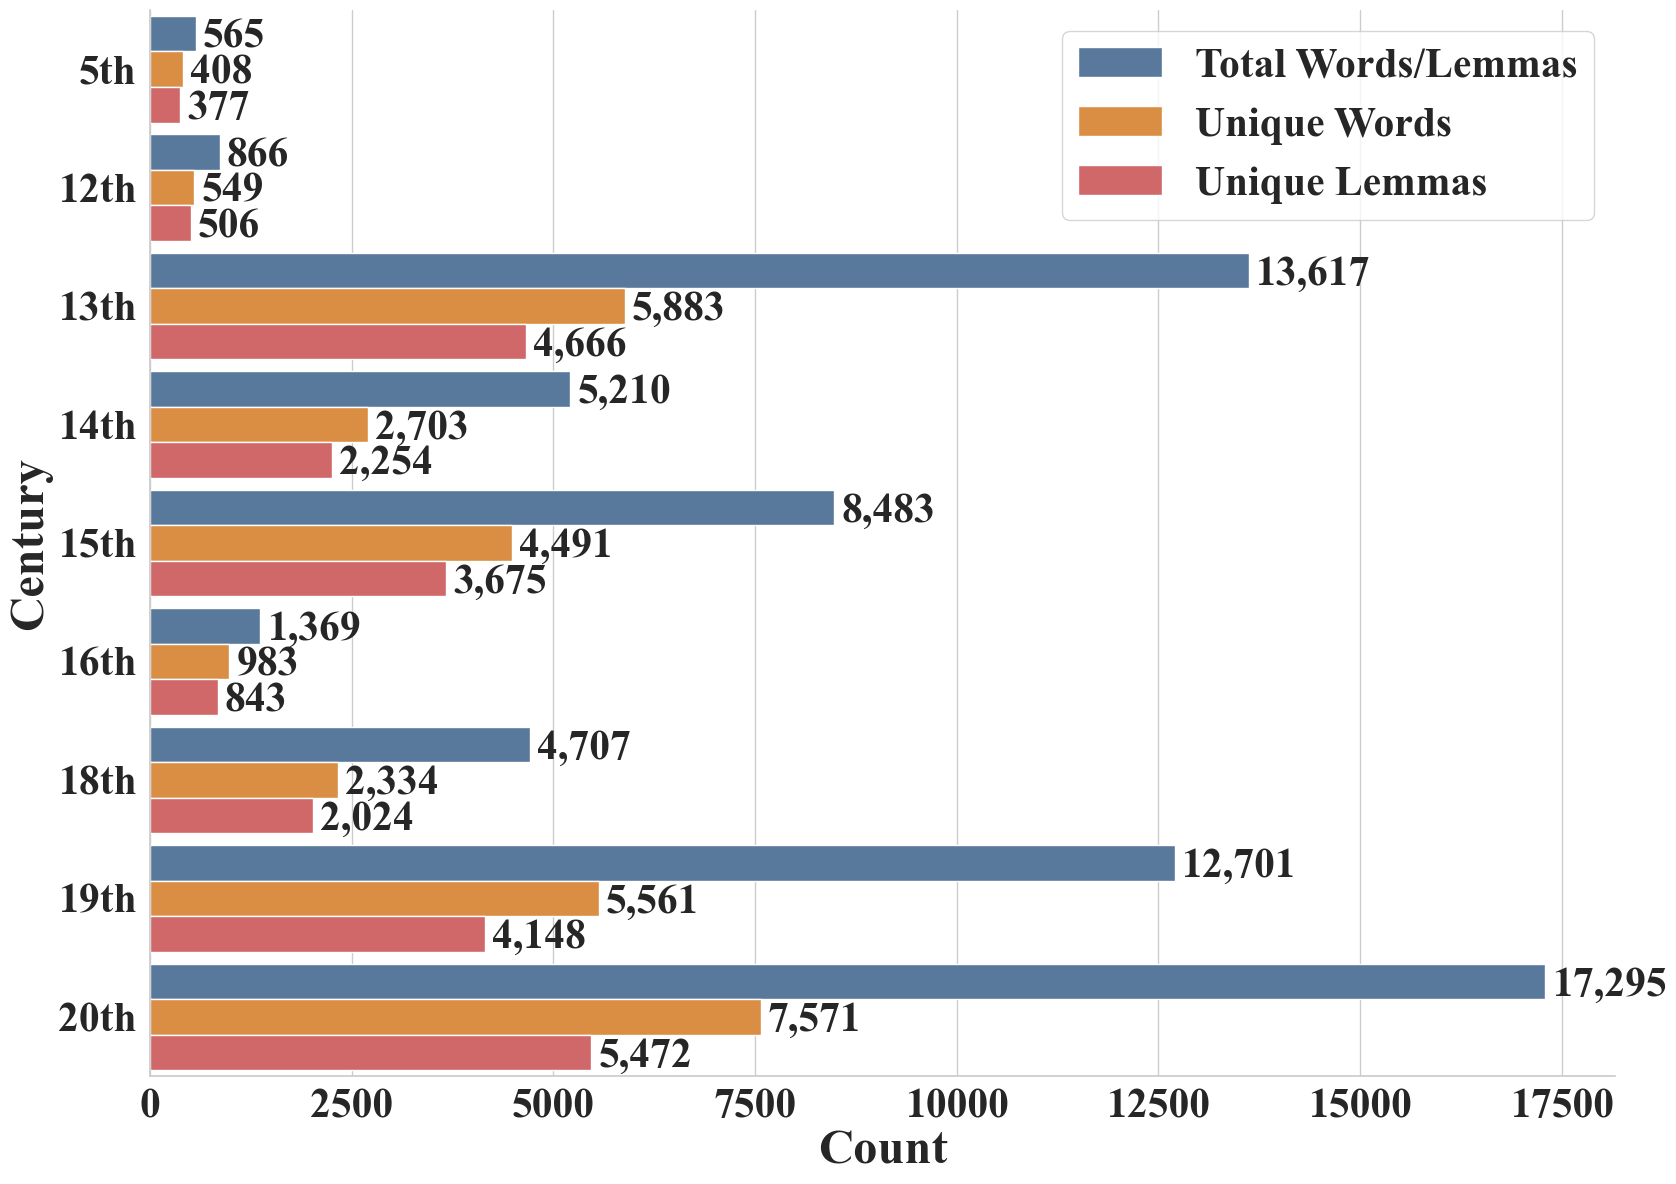

In [78]:
df_melted = stats_df.melt(id_vars='Century', var_name='Metric', value_name='Count')
    
# Set aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Liberation Serif', 'serif']

plt.figure(figsize=(17, 12))

# Create grouped horizontal bar chart
palette = {'Total Words/Lemmas': '#4e79a7', 'Unique Words': '#f28e2b', 'Unique Lemmas': '#e15759'}
ax = sns.barplot(data=df_melted, y='Century', x='Count', hue='Metric', palette=palette, width=0.9)
sns.despine()

# Add data labels
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{int(width):,}', 
                    (width, p.get_y() + p.get_height() / 1.6), 
                    ha='left', va='center', 
                    xytext=(5, 0), 
                    textcoords='offset points',
                    fontsize=30,
                    fontweight='bold')

# plt.title('Word and Lemma Statistics by Century', fontsize=20, fontweight='bold', pad=25)
plt.xlabel('Count', fontsize=35, fontweight='bold')
plt.ylabel('Century', fontsize=35, fontweight='bold')

ax.set_xticklabels(ax.get_xticklabels(), fontsize=30, fontweight='bold')
ax.set_yticklabels(ax.get_yticklabels(), fontsize=30, fontweight='bold')

plt.legend(prop={'size': 30, 'weight': 'bold'}, loc='upper right')

plt.tight_layout()

output_path = '../Data/refined_word_counts.pdf'
plt.savefig(output_path, format='pdf', dpi=300, bbox_inches='tight')
print(f"Refined visualization saved to {output_path}")

In [56]:
century_tokens_lemma.keys()

dict_keys(['5', '12', '13', '14', '15', '16', '18', '19', '20'])

In [57]:
# century_tokens_lemma['13']

In [58]:
centuries_to_compare_1 = ['13', '14', '15' ,'16', '18', '19', '20']
centuries_to_compare_2 = ['13', '14', '15' , '18', '19', '20']

In [59]:
consistent_keys_lemmas = get_consistent_keys_from_sentence_lists(century_tokens_lemma, centuries_to_compare_2)

In [60]:
len(consistent_keys_lemmas)

261

In [61]:
consistent_keys_lemmas = [word for word in consistent_keys_lemmas if is_sinhala(word)]

In [62]:
len(consistent_keys_lemmas)

261

In [63]:
with open("../Data/consistent_keys_lemmas.json", "w", encoding="utf-8") as f:
    json.dump(list(consistent_keys_lemmas), f, ensure_ascii=False, indent=4)